In [15]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.dummy import DummyRegressor
from xgboost import cv
from sklearn.model_selection import cross_val_score, KFold
from sklearn.feature_selection import mutual_info_regression
from sklearn.model_selection import cross_val_predict
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import Lasso, Ridge

df_test = pd.read_csv('../data/test.csv')
df_train = pd.read_csv('../data/train.csv')

df_summary = pd.DataFrame({'dtype': df_train.dtypes, 'nulls': df_train.isna().sum(), 'nununique': df_train.nunique(), 'sample_1': df_train.iloc[0], 'sample_2': df_train.iloc[1], 'sample_3': df_train.iloc[2]})
df_summary

,dtype,nulls,nununique,sample_1,sample_2,sample_3
Id,int64,0,1460,1,2,3
MSSubClass,int64,0,15,60,20,60
MSZoning,str,0,5,RL,RL,RL
LotFrontage,float64,259,110,65.0,80.0,68.0
LotArea,int64,0,1073,8450,9600,11250
...,...,...,...,...,...,...
MoSold,int64,0,12,2,5,9
YrSold,int64,0,5,2008,2007,2008
SaleType,str,0,9,WD,WD,WD
SaleCondition,str,0,6,Normal,Normal,Normal


In [16]:
RANDOM_STATE = 42
N_SPLITS = 5
MAX_OVERFIT_GAP = 0.05


In [17]:
def add_feature(df):
    df['Total_SF'] = df['GrLivArea'] + df['TotalBsmtSF']
    df['Total_Bathrooms'] = df['BsmtFullBath'] + 0.5 * df['BsmtHalfBath'] + df['FullBath'] + 0.5 * df['HalfBath']
    df['AgeAtSale'] = df['YrSold'] - df['YearBuilt']
    df['GarageSFPerCar'] = df['GarageArea'] / df['GarageCars']
    return df

In [18]:
df_train = add_feature(df_train)
df_test = add_feature(df_test)

c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning:

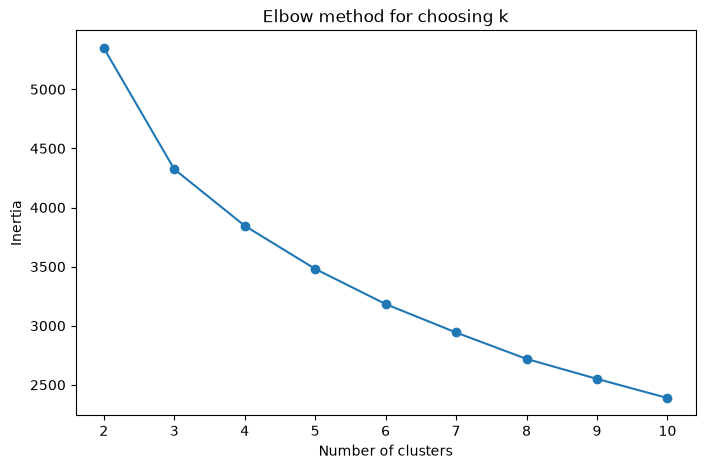

c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


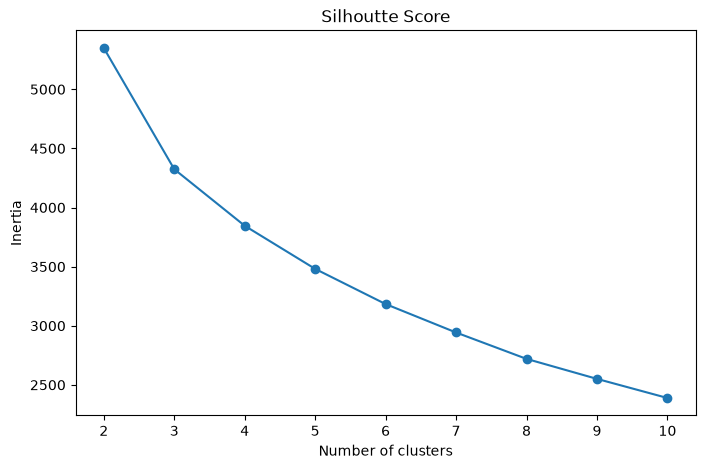

c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


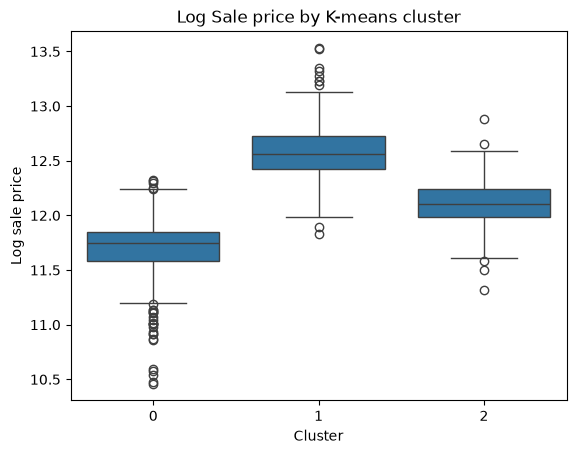

In [19]:


cluster_cols = ['GrLivArea', 'OverallQual', 'YearBuilt', 'GarageCars', 'TotalBsmtSF', 'Total_SF']

X_cluster = df_train[cluster_cols].copy()
X_cluster = X_cluster.fillna(X_cluster.median())
scaler = StandardScaler()
X_cluster_scaled = scaler.fit_transform(X_cluster)

inertias = []

for k in range (2,11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
    kmeans.fit(X_cluster_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(2,11), inertias, marker='o')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow method for choosing k')
plt.xticks(range(2,11))
plt.show()


silhoutte_scores = []
for k in range(2,11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )
cluster_labels = kmeans.fit_predict(X_cluster_scaled)

score = silhouette_score(
    X_cluster_scaled,
    cluster_labels
)

silhoutte_scores.append(score)

plt.figure(figsize=(8,5))
plt.plot(
    range(2,11),
    inertias,
    marker='o'
)

plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Silhoutte Score')
plt.xticks(range(2,11))
plt.show()
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

cluster_labels = final_kmeans.fit_predict(X_cluster_scaled)

cluster_analysis = df_train[cluster_cols + ['SalePrice']]
cluster_analysis['Cluster'] = cluster_labels
cluster_analysis['LogSalePrice'] = np.log1p(cluster_analysis['SalePrice'])

cluster_summary = (
    cluster_analysis.groupby('Cluster').agg(
        house_count=('SalePrice', 'size')
        , avergae_grlivarea=('GrLivArea', 'mean'),
        average_quality=('OverallQual', 'mean'),
        average_year_built=('YearBuilt', 'mean'),
        average_total_sf=('Total_SF', 'mean'),
        median_log_price=('LogSalePrice', 'median')
    ).sort_values('median_log_price')
)

cluster_summary
train_distances = final_kmeans.transform(X_cluster_scaled)




sns.boxplot(data=cluster_analysis, x='Cluster', y='LogSalePrice')
plt.title('Log Sale price by K-means cluster')
plt.xlabel('Cluster')
plt.ylabel('Log sale price')
plt.show()

In [20]:
num_cols = df_train.select_dtypes(include='number').columns.tolist()

cat_cols = df_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

ord_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageCond', 'GarageQual', 'PoolQC', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']

cat_cols = [col for col in cat_cols if col not in ord_cols]

ord_cols = [col for col in ord_cols if col in df_train.columns]

num_cols = [col for col in num_cols if col != 'SalePrice' and col != 'Id']

quality_order = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
quality_order_none = ['None'] + quality_order
exposure_none_order = ['None', 'No', 'Mn', 'Av', 'Gd']
finish_none_order = ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ']
pool_none_order = ['None', 'Fa', 'Gd', 'Ex']

regular_ord_cols = ['ExterQual', 'ExterCond', 'HeatingQC', 'KitchenQual']
none_ord_cols = ['BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'BsmtQual', 'BsmtCond', 'GarageCond', 'GarageQual', 'PoolQC', 'FireplaceQu']
print(cat_cols)
none_cat_cols = ['Alley', 'MasVnrType', 'GarageType', 'GarageFinish', 'Fence', 'MiscFeature']
regular_cat_cols = [col for col in cat_cols if col not in none_cat_cols]


ordinal_categories = {
    'ExterQual': quality_order,
    'ExterCond': quality_order,
    'BsmtQual': quality_order_none,
    'BsmtCond': quality_order_none,
    'HeatingQC': quality_order,
    'KitchenQual': quality_order,
    'FireplaceQu': quality_order_none,
    'GarageCond': quality_order_none,
    'GarageQual': quality_order_none,
    'PoolQC': pool_none_order,
    'BsmtExposure': exposure_none_order,
    'BsmtFinType1': finish_none_order,
    'BsmtFinType2': finish_none_order
}

regular_categories = [ordinal_categories[col] for col in regular_ord_cols]
none_categories = [ordinal_categories[col] for col in none_ord_cols]

['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir', 'Electrical', 'Functional', 'GarageType', 'GarageFinish', 'PavedDrive', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


C:\Users\yazid\AppData\Local\Temp\ipykernel_6460\1231841208.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_train.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()


In [21]:

X_train = df_train.drop(columns=['SalePrice', 'Id'])
X_test = df_test.drop(columns=['Id'])
y_train = np.log1p(df_train['SalePrice'])
test_id = df_test['Id']

In [22]:
def build_preprocessor(
    num_cols,
    regular_cat_cols,
    none_cat_cols,
    regular_ord_cols,
    none_ord_cols,
    regular_categories,
    none_categories
):
    num_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
    regular_cat_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))])
    none_cat_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='constant', fill_value='None')), ('onehot', OneHotEncoder(sparse_output=False, handle_unknown='ignore'))])
    regular_ord_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='most_frequent')), ('ordinal', OrdinalEncoder(categories=regular_categories, handle_unknown='use_encoded_value', unknown_value=-1))])
    none_ord_pipeline = Pipeline(steps=[('impute', SimpleImputer(strategy='constant', fill_value='None')), ('ordinal', OrdinalEncoder(categories=none_categories, handle_unknown='use_encoded_value', unknown_value=-1))])
    return ColumnTransformer(transformers=[('num', num_pipeline, num_cols), ('regular_cat', regular_cat_pipeline, regular_cat_cols), ('none_cat', none_cat_pipeline, none_cat_cols), ('regular_ord', regular_ord_pipeline, regular_ord_cols), ('none_ord', none_ord_pipeline, none_ord_cols)])

In [23]:
preprocessor = build_preprocessor(num_cols=num_cols, regular_cat_cols=regular_cat_cols, none_cat_cols=none_cat_cols, regular_ord_cols=regular_ord_cols, none_ord_cols=none_ord_cols, regular_categories=regular_categories, none_categories=none_categories)

def build_pipeline(preprocessor, model):
    return Pipeline(steps=[('preprocessor', preprocessor), ('model', model)])


In [24]:

cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)



def evaluate_model(model_name, model):
    pipeline = build_pipeline(preprocessor=preprocessor, model=model)
    msle = -cross_val_score(estimator=pipeline, X=X_train, y=y_train, scoring='neg_mean_squared_error', cv=cv, n_jobs=-1)
    rmsle_scores = np.sqrt(msle)
    
    return {
        'model': model_name,
        'mean_rmsle': rmsle_scores.mean(),
        'std_rmsle': rmsle_scores.std()
    }

In [25]:
def select_best_result(results, max_overfit_gap=MAX_OVERFIT_GAP):
    accepted_results = results[results['overfit_gap'] <= max_overfit_gap]

    if accepted_results.empty:
        raise ValueError(
            'No model passed the maximum overfit gap'
        )
    best_index = accepted_results['validation_rmsle'].idxmin()
    return results.loc[best_index]

In [26]:
def tune_model(
    model_name, 
    model,
    parameter_distributions,
    n_iter=30
):
    pipeline = build_pipeline(preprocessor=preprocessor, model=model)
    
    search = RandomizedSearchCV(
        estimator=pipeline, 
        param_distributions=parameter_distributions,
        n_iter=n_iter,
        scoring='neg_mean_squared_error',
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        return_train_score=True,
        refit=False,
        error_score='raise'
    )
    search.fit(X_train, y_train)
    
    results = pd.DataFrame(search.cv_results_)
    
    results['train_rmsle'] = np.sqrt(
        -results['mean_train_score']
    )
    
    results['validation_rmsle'] = np.sqrt(
        -results['mean_test_score']
    )
    
    results['overfit_gap'] = (
        results['validation_rmsle'] - results['train_rmsle']
    )
    
    results['model'] = model_name
    best_result = select_best_result(results=results)
    
    return search, results, best_result

In [31]:



models= {
    'xgboost': XGBRegressor(
        random_state=RANDOM_STATE
    ),
    'extra_trees': ExtraTreesRegressor(
        n_estimators=500,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    'random_forest': RandomForestRegressor(
        n_estimators=500,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    'lasso': Lasso(
        alpha=0.5,
        max_iter=10000
    ),
    'ridge': Ridge(
        alpha=1,
        max_iter=10000
    )
}


In [28]:
model_comparison = []

for model_name, model in models.items():
    result = evaluate_model(
        model_name=model_name,
        model=model
    )
    model_comparison.append(result)
    
model_comparison_df = pd.DataFrame(model_comparison).sort_values('mean_rmsle')

model_comparison_df

,model,mean_rmsle,std_rmsle
1,extra_trees,0.135872,0.013113
2,random_forest,0.143021,0.018481
4,Ridge,0.143651,0.038727
0,xgboost,0.146970,0.019873
3,Lasso,0.398782,0.025132


In [29]:
def get_dummy_baseline():
    baseline = DummyRegressor(strategy='mean')

    baseline_scores = cross_val_score(
        baseline, 
        X_train,
        y_train,
        cv=cv,
        scoring='neg_mean_squared_error'
    )
    baseline_rmsle = np.sqrt(-baseline_scores.mean())
    return baseline_rmsle

In [32]:
model_params = {'xgboost': {
    'model__n_estimators': [100, 300, 600, 1000],
    'model__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__max_depth': [2,3,4,5,6],
    'model__min_child_weight': [1,3,5],
    'model__subsample': [0.8,0.9,1.0]
}
,
'extra_trees': {
    'model__n_estimators': [300, 500, 800],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2,5,10],
    'model__min_samples_leaf': [1,2,4],
    'model__max_features': [1.0, 'sqrt', 'log2']
},
'random_forest': {
    'model__n_estimators': [300,500,800],
    'model__max_depth': [None, 10, 20, 30],
    'model__min_samples_split': [2,5,10],
    'model__min_samples_leaf': [1,2,4],
    'model__max_features': [1.0, 'sqrt', 'log2']
},
'lasso': {
    'model__alpha': np.logspace(-4, -2, 5)
},
'ridge': {
    'model__alpha': np.logspace(0, 2, 5)
}
}

searches = {}
tuning_results = []
best_results = []

for model_name, model in models.items():
    search, results, best_result = tune_model(
        model_name=model_name,
        model=model,
        parameter_distributions=model_params[model_name]
        , n_iter=30
    )
    searches[model_name] = search
    tuning_results.append(results)
    best_results.append(best_result)
    
all_tuning_results = pd.concat(tuning_results, ignore_index=True)

best_results_df = pd.DataFrame(best_results).sort_values('validation_rmsle')

searches

c:\Users\yazid\anaconda3\envs\ds_env\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 5 is smaller than n_iter=30. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


{'xgboost': RandomizedSearchCV(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                    error_score='raise',
                    estimator=Pipeline(steps=[('preprocessor',
                                               ColumnTransformer(transformers=[('num',
                                                                                Pipeline(steps=[('impute',
                                                                                                 SimpleImputer(strategy='median')),
                                                                                                ('scale',
                                                                                                 StandardScaler())]),
                                                                                ['MSSubClass',
                                                                                 'LotFrontage',
                                                                       

In [33]:
best_results_df[['model', 'train_rmsle', 'validation_rmsle', 'overfit_gap', 'params']]

,model,train_rmsle,validation_rmsle,overfit_gap,params
3,xgboost,0.087076,0.129323,0.042247,"{'model__subsample': 0.8, 'model__n_estimators..."
17,random_forest,0.096707,0.146580,0.049873,"{'model__n_estimators': 800, 'model__min_sampl..."
1,lasso,0.101128,0.147014,0.045886,{'model__alpha': 0.00031622776601683794}
0,ridge,0.100037,0.148779,0.048743,{'model__alpha': 1.0}
26,extra_trees,0.118496,0.161429,0.042933,"{'model__n_estimators': 800, 'model__min_sampl..."


In [47]:
best_params = best_results_df.iloc[0]['params']
full_pipeline = build_pipeline(preprocessor=preprocessor, model=XGBRegressor(random_state=RANDOM_STATE))
full_pipeline.set_params(**best_params)
full_pipeline.fit(X_train, y_train)
predict_log = full_pipeline.predict(X_test)
predict = np.expm1(predict_log)
submission = pd.DataFrame({'Id':test_id, 'SalePrice':predict})
submission.to_csv('../submission.csv', index=False)


In [ ]:
numeric_df = df_train.select_dtypes(include='number').copy()

numeric_df['LogSalePrice'] = np.log1p(numeric_df['SalePrice'])

correlations = (numeric_df.corr()['LogSalePrice'].drop('LogSalePrice').sort_values(key=abs, ascending=False))

print(correlations.head(15))

In [ ]:
car_size = pd.DataFrame(df_train['GarageArea'] / df_train['GarageCars'])
car_size

In [ ]:


numeric_cols = df_train.select_dtypes(include='number').columns.tolist()
numeric_cols.remove('SalePrice')
numeric_cols.remove('Id')
X_numeric = df_train[numeric_cols].copy()

X_numeric = X_numeric.fillna(X_numeric.median())

y_log = np.log1p(df_train['SalePrice'])
mi_scores = mutual_info_regression(X_numeric, y_log, random_state=42)

mi_results = (
    pd.Series(mi_scores, index=numeric_cols).sort_values(ascending=False)
)

print(mi_results.head(20))

In [ ]:


plot_data = df_train.copy()
plot_data['LogSalePrice'] = np.log1p(plot_data['SalePrice'])

fig, axes = plt.subplots(1, 2, figsize=(16,8))

sns.scatterplot(data=plot_data,
                x='GarageArea', 
                y='LogSalePrice',
                ax=axes[0])

axes[0].set_title('GarageArea vs Log SalePrice')

sns.boxplot(data=plot_data, x='GarageCars', y='LogSalePrice', ax=axes[1])

axes[1].set_title('GarageCars vs Log SalePrice')
plt.tight_layout()
plt.savefig('garage_vis.png', bbox_inches='tight')
plt.show()



In [ ]:


predicted_prices = cross_val_predict(
    full_pipeline,
    X_train,
    y_train,
    cv=cv,
    method='predict'
)

errors = y_train - predicted_prices
absolute_errors = errors.abs()

error_analysis = df_train.copy()
error_analysis['ActualLogPrice'] = y_train
error_analysis['PredictedLogPrice'] = predicted_prices
error_analysis['Error'] = errors
error_analysis['AbsoluteError'] = absolute_errors
error_analysis.sort_values('AbsoluteError', ascending=False).head(20)

sns.scatterplot(x=error_analysis['PredictedLogPrice'], y=error_analysis['Error'])

plt.axhline(0, color='red', linestyle='--')
plt.xlabel('Predicted log price')
plt.ylabel('Prediction error')
plt.title('Prediction errors')
plt.show()

In [ ]:
sns.boxplot(data=error_analysis, x='OverallQual', y='Error')
plt.axhline(0, color='red', linestyle='--')
plt.title('Prediction error by overall quality')
plt.show()